In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import pickle

import sys
sys.path.append('../../../')

# Import methods
from QGP.Soliton_Gen import *
from Utilities import *

import config
i = 1j

path = "../../../Heaven_scripts/Results/Blow_up/Time/blow_up_A_0.65_sigma_0.1_Nts_new/"
path_save = "Img/Heaven/Time/"

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
A = 0.65
sigma = 1/10

def gaussian(x, A):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

def sech(x):
    output = 1/np.cosh(x)
    return output

def sech_init(x, A):
    output = A * sech(1/np.sqrt(sigma) * x)
    return output
    
L = np.pi
k = 1
tf = 2.25e-3

In [4]:
Nts = np.array([2_000, 4_000, 8_000, 16_000, 32_000, 64_000, 128_000])
N = 200_000

base = "blow_up"
norms_inf = []
H1_norms = []
H2_norms = []
energies = []
ts = []

for Nt in Nts:
    folder_name = path + "blow_up_Nt_{Nt}/".format(Nt=Nt)
    norm_inf_file = gzip.GzipFile(folder_name + "norm_inf.npy.gz", "r")
    norm_inf = np.load(norm_inf_file)
    norms_inf += [norm_inf]

    H1_norm_file = gzip.GzipFile(folder_name + "H1_norm.npy.gz", "r")
    H1_norm = np.load(H1_norm_file)
    H1_norms += [H1_norm]

    H2_norm_file = gzip.GzipFile(folder_name + "H2_norm.npy.gz", "r")
    H2_norm = np.load(H2_norm_file)
    H2_norms += [H2_norm]

    energy_file = gzip.GzipFile(folder_name + "energy.npy.gz", "r")
    energy = np.load(energy_file)
    energies += [energy]
    
    t_file = gzip.GzipFile(folder_name + "time.npy.gz", "r")
    t = np.load(t_file)
    ts += [t]

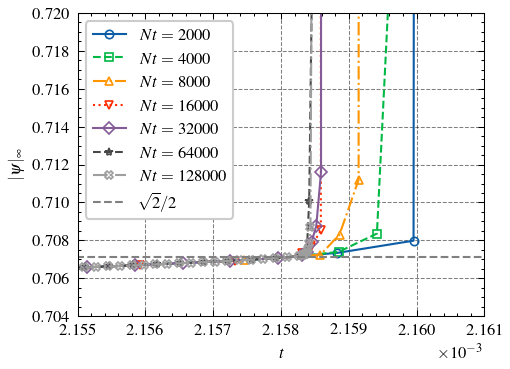

In [5]:
sol_lim = np.sqrt(2)/2+0.000085
for j in range(len(Nts)):
    Nt = Nts[j]
    norm_inf = norms_inf[j]

    cond = norm_inf!=0
    norm_inf = norm_inf[cond]

    cond_1_markers = np.where(norm_inf<sol_lim)[0]
    mark_indices_1 = cond_1_markers[::10]
    cond_2_markers = np.where(norm_inf>sol_lim)[0]
    mark_indices_2 = cond_2_markers
    mark_indices = np.append(mark_indices_1, mark_indices_2)

    plt.plot(ts[j][cond], norm_inf, label=r"$Nt = {}$".format(Nt), markevery=mark_indices, markerfacecolor='none')

plt.hlines(np.sqrt(2)/2, 0, 3.5e-3, ls="--", color="gray", label=r"$\sqrt{2}/2$")
plt.legend()
plt.xlabel(r"$t$")
plt.ylabel(r"$|\psi|_\infty$")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.ylim(0.704, 0.72)
#plt.xlim(2.1e-3, 2.17e-3)
plt.xlim(2.155e-3, 2.161e-3)

plt.savefig(path_save+"Blow_up_Nt_inf_norm.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Blow_up_Nt_inf_norm.pgf", dpi=300, bbox_inches = "tight")
plt.show()

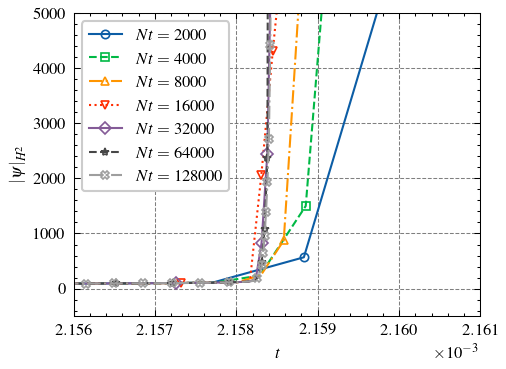

In [6]:
sol_lim = np.sqrt(2)/2+0.000085
for j in range(len(Nts)):
    Nt = Nts[j]
    cond = H2_norms[j]!=0
    norm_inf = norms_inf[j]

    cond_inf = norm_inf!=0
    norm_inf = norm_inf[cond_inf]

    cond_1_markers = np.where(norm_inf<sol_lim)[0]
    mark_indices_1 = cond_1_markers[::20]
    cond_2_markers = np.where(norm_inf>sol_lim)[0]
    mark_indices_2 = cond_2_markers
    mark_indices = np.append(mark_indices_1, mark_indices_2)

    plt.plot(ts[j][cond], H2_norms[j][cond], label=r"$Nt = {}$".format(Nt), markevery=mark_indices, markerfacecolor='none')

plt.legend()
plt.xlabel(r"$t$")
plt.ylabel(r"$|\psi|_{H^2}$")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.ylim(-500, 5000)
plt.xlim(2.156e-3, 2.161e-3)

plt.savefig(path_save+"Blow_up_Nt_H2_norm.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Blow_up_Nt_H2_norm.pgf", dpi=300, bbox_inches = "tight")
plt.show()

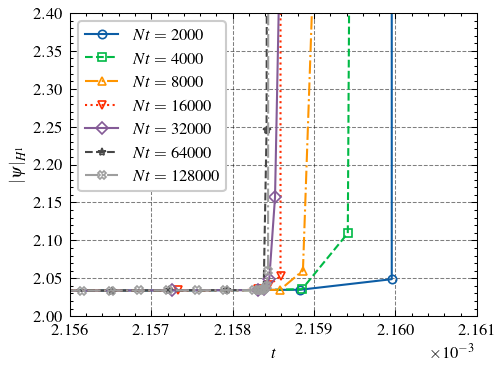

In [7]:
sol_lim = np.sqrt(2)/2+0.000085
for j in range(len(Nts)):
    Nt = Nts[j]
    cond = H1_norms[j]!=0
    norm_inf = norms_inf[j]

    cond_inf = norm_inf!=0
    norm_inf = norm_inf[cond_inf]

    cond_1_markers = np.where(norm_inf<sol_lim)[0]
    mark_indices_1 = cond_1_markers[::20]
    cond_2_markers = np.where(norm_inf>sol_lim)[0]
    mark_indices_2 = cond_2_markers
    mark_indices = np.append(mark_indices_1, mark_indices_2)

    plt.plot(ts[j][cond], H1_norms[j][cond], label=r"$Nt = {}$".format(Nt), markevery=mark_indices, markerfacecolor='none')

plt.legend()
plt.xlabel(r"$t$")
plt.ylabel(r"$|\psi|_{H^1}$")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.ylim(2, 2.4)
plt.xlim(2.156e-3, 2.161e-3)

plt.savefig(path_save+"Blow_up_Nt_H1_norm.pdf", dpi=300, bbox_inches = "tight")
plt.savefig(path_save+"Blow_up_Nt_H1_norm.pgf", dpi=300, bbox_inches = "tight")
plt.show()

In [112]:
ts_blow = []
for j in range(len(Nts)):
    idx_blow_up = np.where(np.abs(np.gradient(energies[j]))>.5)[0][0] #np.argmax(np.gradient(energies[j]))
    ts_blow += [ts[j][idx_blow_up]]

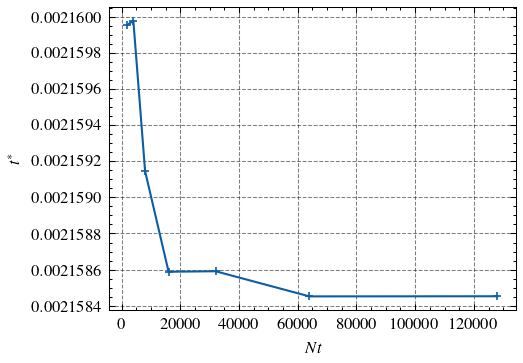

In [113]:
plt.plot(Nts, ts_blow, "+-")
plt.xlabel(r"$Nt$")
plt.ylabel(r"$t^*$")
plt.show()